# 02 · Factorización de matrices

**Objetivo:** modelar cada usuario y cada ítem con $k$ factores latentes, $\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i$,
entrenar con SGD y con mínimos cuadrados alternados (ALS), y ver qué controla la dimensión $k$ y la
regularización. En datos sintéticos se puede comprobar si el modelo **recupera** la estructura real.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from applied_recsys.baselines import BiasModel
from applied_recsys.data import random_split, to_csr
from applied_recsys.synthetic import synthetic_ratings

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_recsys.factorization import ExplicitALS, FunkSVD

df, truth = synthetic_ratings(
    n_users=1500, n_items=800, density=0.06, rank=5, noise=0.5, mnar=0.0, signal=4.0, seed=1
)
shape = (1500, 800)
tr, te = random_split(df, 0.2, seed=0)
Rtr, Rte = to_csr(tr, shape), to_csr(te, shape)
u, i, y = te.u.to_numpy(), te.i.to_numpy(), te.rating.to_numpy()
bias = BiasModel().fit(Rtr)


def rmse(p):
    return np.sqrt(np.mean((y - np.clip(p, 1, 5)) ** 2))


floor = rmse(truth["true"][u, i])  # predecir con el gusto real: solo queda ruido + redondeo
print(f"piso (predecir con el gusto real): RMSE {floor:.4f}")
print(f"sesgos:                            RMSE {rmse(bias.predict(u, i)):.4f}")

piso (predecir con el gusto real): RMSE 0.4866
sesgos:                            RMSE 1.3281


## 1. SGD: curva de validación por época

λ = 0.0: mínimo 0.8450 en época 15, final 0.9345


λ = 0.05: mínimo 0.7494 en época 26, final 0.7542


λ = 0.2: mínimo 0.8301 en época 40, final 0.8301


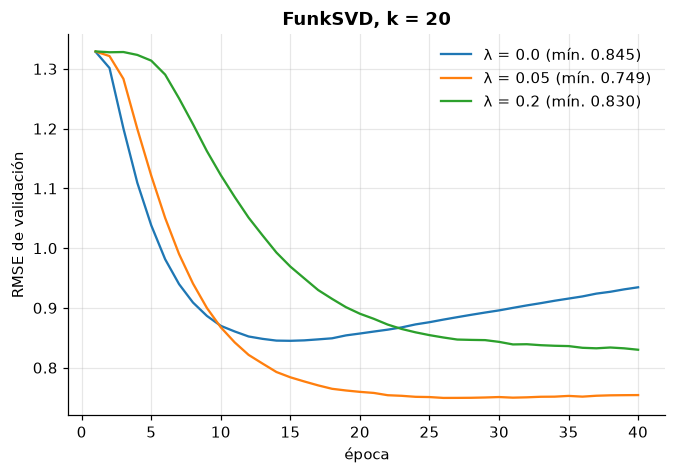

In [2]:
fig, ax = plt.subplots()
for reg in [0.0, 0.05, 0.2]:
    m = FunkSVD(k=20, lr=0.02, reg=reg, epochs=40, batch=512).fit(Rtr, Rte)
    ax.plot(range(1, 41), m.history, label=f"λ = {reg} (mín. {min(m.history):.3f})")
    best = int(np.argmin(m.history))
    print(f"λ = {reg}: mínimo {m.history[best]:.4f} en época {best + 1}, final {m.history[-1]:.4f}")
ax.set(xlabel="época", ylabel="RMSE de validación", title="FunkSVD, k = 20")
ax.legend();

- **λ = 0**: la validación toca fondo en la época 15 (0.845) y luego sube a 0.934: con 20 factores para
  una estructura de rango 5, el modelo memoriza el ruido.
- **λ = 0.05**: el mejor (0.749), estable hasta el final.
- **λ = 0.2**: subajusta (0.830): la penalización no deja aprender los factores.

## 2. ALS: dimensión latente $k$

ALS alterna dos regresiones ridge con solución cerrada; cada paso no empeora la pérdida.

k =  1: RMSE 1.2228
k =  2: RMSE 1.1081
k =  3: RMSE 1.0075
k =  5: RMSE 0.7433
k =  8: RMSE 0.7620
k = 16: RMSE 0.7863
k = 32: RMSE 0.7959


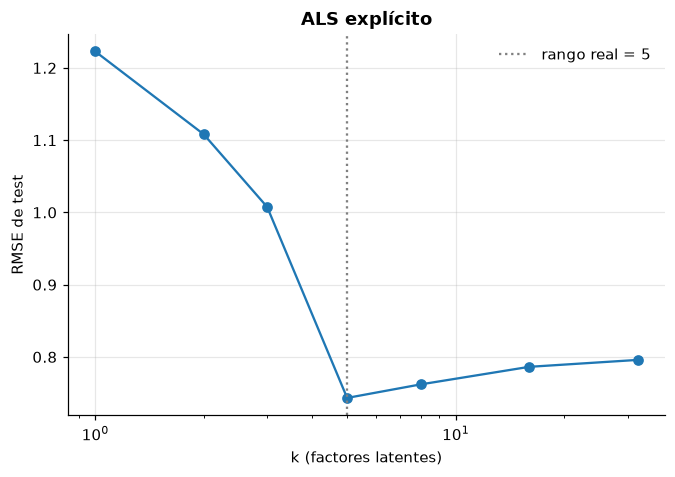

In [3]:
ks = [1, 2, 3, 5, 8, 16, 32]
errs = [rmse(ExplicitALS(k=k, reg=0.1, n_iter=10).fit(Rtr, bias).predict(u, i)) for k in ks]
fig, ax = plt.subplots()
ax.plot(ks, errs, "o-")
ax.axvline(5, color="gray", ls=":", label="rango real = 5")
ax.set(xscale="log", xlabel="k (factores latentes)", ylabel="RMSE de test", title="ALS explícito")
ax.legend()
for k, e in zip(ks, errs, strict=True):
    print(f"k = {k:>2}: RMSE {e:.4f}")

- El error baja fuerte hasta **k = 5, el rango real** (0.743), y luego sube un poco: los factores
  extra modelan ruido.
- Los sesgos solos dan 1.328; el piso (predecir con el gusto real) es 0.487. La factorización cierra
  la mayor parte de esa brecha.

## 3. ¿Recupera la estructura real?

Los factores latentes solo están definidos salvo rotación, así que no se comparan uno a uno. Lo que sí
se puede comparar es el **subespacio**: los ángulos principales entre el espacio de los factores reales
de los ítems y el aprendido (coseno 1 = mismo subespacio).

In [4]:
from scipy.linalg import subspace_angles

als = ExplicitALS(k=5, reg=0.1, n_iter=15).fit(Rtr, bias)
angles = subspace_angles(truth["Q"], als.Q)
print("coseno de los ángulos principales:", np.round(np.cos(angles), 3))
rand = subspace_angles(truth["Q"], rng.normal(size=als.Q.shape))
print("con factores aleatorios:          ", np.round(np.cos(rand), 3))

coseno de los ángulos principales: [0.905 0.912 0.92  0.925 0.934]
con factores aleatorios:           [0.01  0.047 0.08  0.124 0.161]


## Para llevar

- La factorización comprime gustos en $k$ dimensiones; $k$ y λ controlan el balance sesgo–varianza.
- SGD: simple y escalable, sensible a tasa y épocas. ALS: sin tasa de aprendizaje, paralelizable,
  natural cuando el problema es de mínimos cuadrados (y para datos implícitos, notebook 03).
- Con datos reales no hay “verdad” que recuperar: elegir $k$ y λ con una validación temporal.